In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import hashlib
import os
import platform
import uuid

STUDENT_ID = 20244320114
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] pyexp
[学号] 20244320114
[机器指纹] 2a9f8f4b934fcb62
[RUN_ID] 20244320114-2a9f8f4b934fcb62


围绕半圆定律

编写函数wigner_density(x)

In [2]:
def wigner_density(x):
    if abs(x) <= 2:
        return 1/(2*np.pi) * np.sqrt(4 - x**2)
    else:
        return 0.0

# 测试
print(wigner_density(0))
print(wigner_density(3))
print(wigner_density(2))

0.3183098861837907
0.0
0.0


编写generate_wigner(n)

In [3]:
def generate_wigner(n):
    # 判断是否为正整数
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n必须是正整数")
    # 初始化n*n零矩阵
    Z = np.zeros((n, n))
    sigma = np.sqrt(1.0 / n)
    for i in range(n):
        for j in range(i, n):
            val = np.random.normal(loc=0, scale=sigma)
            Z[i, j] = val
            Z[j, i] = val
    return Z

# 测试
mat = generate_wigner(5)
print(mat)
print(np.allclose(mat, mat.T)) # 判断是否对称，输出True代表正确


[[-0.45763601  0.30025702  0.43061709 -0.3041574  -0.4359251 ]
 [ 0.30025702  0.16644367  0.55302032  0.03600397  0.81862207]
 [ 0.43061709  0.55302032 -0.20361145 -0.78343133  0.20257482]
 [-0.3041574   0.03600397 -0.78343133 -0.07461855  0.09760612]
 [-0.4359251   0.81862207  0.20257482  0.09760612 -0.06628043]]
True


编写get_spectrum(matrix)

In [4]:
def get_spectrum(matrix):
    eigvals = np.linalg.eigvalsh(matrix)
    return eigvals

# 测试
m = generate_wigner(10)
eigs = get_spectrum(m)
print(eigs)
print(np.all(np.diff(eigs)>=0)) # 检查非递减排序

[-1.50576636 -1.31245839 -1.02238928 -0.55181413 -0.01793853  0.12026966
  0.23498423  0.85774548  1.2404387   1.5010146 ]
True


画图

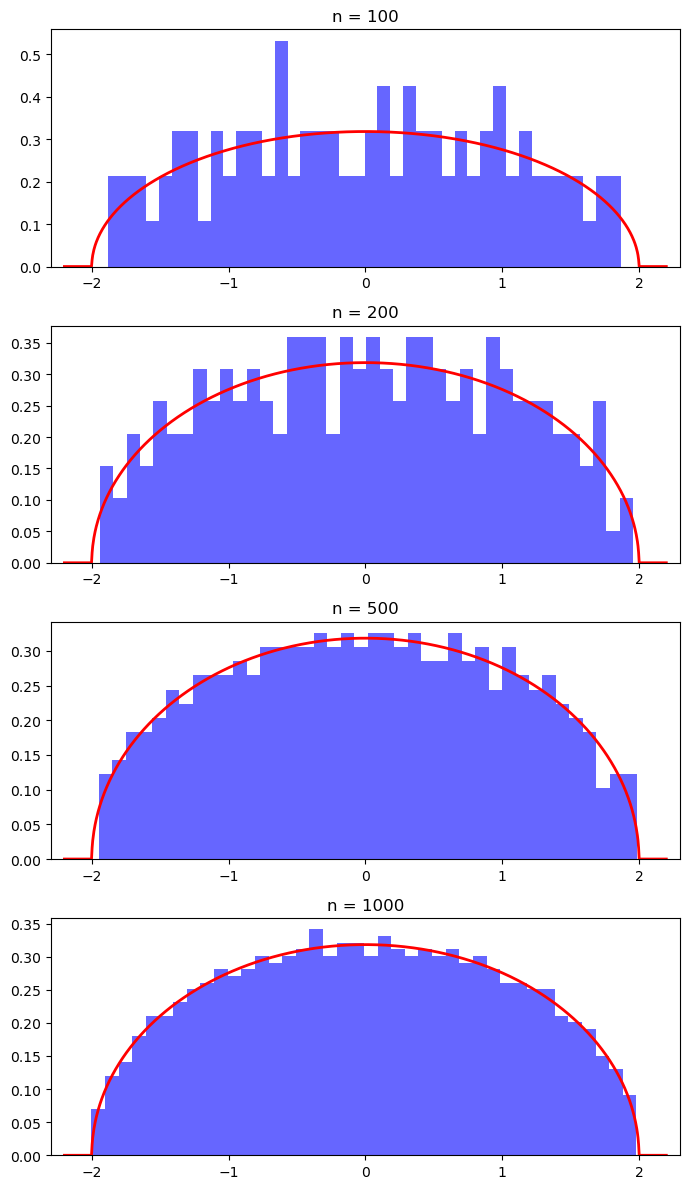

In [5]:
ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(7, 12))

for ax, n in zip(axes, ns):
    w_mat = generate_wigner(n)
    evs = get_spectrum(w_mat)
    # 蓝色标准化直方图
    ax.hist(evs, bins=40, density=True, color="blue", alpha=0.6)
    # 画红色半圆密度曲线
    xs = np.linspace(-2.2, 2.2, 1000)
    ys = np.array([wigner_density(t) for t in xs])
    ax.plot(xs, ys, color="red", lw=2)
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.3, 2.3)

plt.tight_layout()
plt.show()

在n接近1000时，直方图与半圆曲线近似拟合，n越小波动越大

Conway的生命游戏

编写is_valid_board(board)

In [6]:
def is_valid_board(board):
    # 是否二维数组
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    # 所有元素只能是0或1
    unique_vals = np.unique(board)
    for v in unique_vals:
        if v not in (0,1):
            return False
    return True

# 测试
ok_board = np.array([[1,0],[0,1]])
bad_board1 = np.array([[1,2],[0,0]])
bad_board2 = np.array([1,0,1])
print(is_valid_board(ok_board))
print(is_valid_board(bad_board1))
print(is_valid_board(bad_board2))

True
False
False


gol_step(board)

In [7]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("棋盘不是有效的生命游戏棋盘")
    m, n = board.shape
    new_board = np.zeros_like(board) # 新建数组存下一代，不改原棋盘
    # 8个邻居偏移
    dirs = [(-1,-1), (-1,0), (-1,1),
            (0,-1),          (0,1),
            (1,-1),  (1,0), (1,1)]
    
    for i in range(m):
        for j in range(n):
            # 统计活邻居数量，环绕边界取模
            live_nei = 0
            for di, dj in dirs:
                ni = (i + di) % m
                nj = (j + dj) % n
                live_nei += board[ni, nj]
            cur = board[i,j]
            if cur == 1:
                # 活细胞
                if live_nei < 2:
                    new_board[i,j] = 0
                elif live_nei ==2 or live_nei ==3:
                    new_board[i,j] =1
                else: # >3
                    new_board[i,j]=0
            else:
                # 死细胞
                if live_nei ==3:
                    new_board[i,j]=1
                else:
                    new_board[i,j]=0
    return new_board

# 测试：方块不会变化
test = np.array([[1,1],[1,1]])
next_test = gol_step(test)
print(next_test)


[[0 0]
 [0 0]]


draw_gol_board(board)

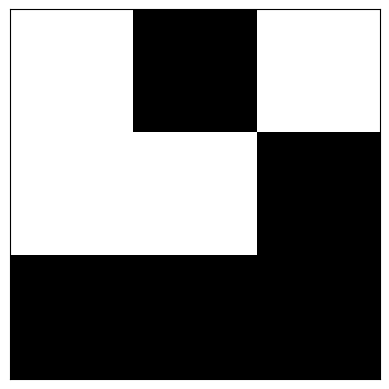

In [8]:
def draw_gol_board(board):
    plt.figure()
    
    plt.imshow(board, cmap="gray_r")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.show()

# 测试绘图
glider = np.array([
    [0,1,0],
    [0,0,1],
    [1,1,1]
])
draw_gol_board(glider)

使用pandas DataFrame

In [9]:
# 读取csv
df = pd.read_csv("iris.csv")
print("基础信息")
print(f"数据点数量(行数): {len(df)}")
print("\n每列数据类型:")
print(df.dtypes)
print("\n全部列名：")
print(df.columns.tolist())
print("\n花卉种类：")
species_unique = df["species"].unique()
print(species_unique)
print(f"花卉种类数目：{len(species_unique)}")


基础信息
数据点数量(行数): 150

每列数据类型:
species                int64
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object

全部列名：
['species', 'sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

花卉种类：
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149]
花卉种类数目：150


修改第35和第38行数据

In [10]:
# 列名行为0 修改索引34
df.loc[34, ["sepal length (cm)","sepal width (cm)","petal length (cm)","petal width (cm)","species"]] = [4.9,3.1,1.5,0.2,"setosa"]
# 修改索引37
df.loc[37, ["sepal length (cm)","sepal width (cm)","petal length (cm)","petal width (cm)","species"]] = [4.9,3.6,1.4,0.1,"setosa"]

# 检查修改结果
print("修改后34行：")
print(df.loc[34])
print("\n修改后37行：")
print(df.loc[37])

修改后34行：
species              setosa
sepal length (cm)       4.9
sepal width (cm)        3.1
petal length (cm)       1.5
petal width (cm)        0.2
Name: 34, dtype: object

修改后37行：
species              setosa
sepal length (cm)       4.9
sepal width (cm)        3.6
petal length (cm)       1.4
petal width (cm)        0.1
Name: 37, dtype: object


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_34296\212482978.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'setosa' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[34, ["sepal length (cm)","sepal width (cm)","petal length (cm)","petal width (cm)","species"]] = [4.9,3.1,1.5,0.2,"setosa"]


添加两列新特征

In [11]:
df["Petal.Ratio"] = df["petal length (cm)"] / df["petal width (cm)"]
df["Sepal.Ratio"] = df["sepal length (cm)"] / df["sepal width (cm)"]

print(df.head())

  species  sepal length (cm)  sepal width (cm)  petal length (cm)  \
0       0                5.1               3.5                1.4   
1       1                4.9               3.0                1.4   
2       2                4.7               3.2                1.3   
3       3                4.6               3.1                1.5   
4       4                5.0               3.6                1.4   

   petal width (cm)  Petal.Ratio  Sepal.Ratio  
0               0.2          7.0     1.457143  
1               0.2          7.0     1.633333  
2               0.2          6.5     1.468750  
3               0.2          7.5     1.483871  
4               0.2          7.0     1.388889  


扩展并保存

In [12]:
df.to_csv("iris_corrected.csv", index=False)

按花卉种类分组，计算新增两项内容的平均值、中位数、最值和标准差

In [13]:
agg_funcs = ["mean", "median", "min", "max", "std"]
group_result = df.groupby("species")[["Petal.Ratio","Sepal.Ratio"]].agg(agg_funcs)
print(group_result)

        Petal.Ratio                                           Sepal.Ratio  \
               mean     median       min        max       std        mean   
species                                                                     
0          7.000000   7.000000  7.000000   7.000000       NaN    1.457143   
1          7.000000   7.000000  7.000000   7.000000       NaN    1.633333   
2          6.500000   6.500000  6.500000   6.500000       NaN    1.468750   
3          7.500000   7.500000  7.500000   7.500000       NaN    1.483871   
4          7.000000   7.000000  7.000000   7.000000       NaN    1.388889   
...             ...        ...       ...        ...       ...         ...   
146        2.631579   2.631579  2.631579   2.631579       NaN    2.520000   
147        2.600000   2.600000  2.600000   2.600000       NaN    2.166667   
148        2.347826   2.347826  2.347826   2.347826       NaN    1.823529   
149        2.833333   2.833333  2.833333   2.833333       NaN    1.966667   